# Denomination or specimen? — paper experiments
Kazakhstan tenge coin classification, two-part study.

- **Part 1 (P1)** — one coin per denomination (`c0`), six background/lighting setups. Varies the *conditions*.
- **Part 2 (P2)** — eight coins per denomination (`c1`–`c8`), one fixed setup (same place, white background, same phone). Varies the *specimen*.

Models in both parts: **Simple CNN** (from scratch), **ResNet18** (ImageNet, fine-tuned), **DINOv2 ViT-S/14** (self-supervised, fine-tuned).

**Experiment 1 — new conditions, same coin.** P1 only: train on setups 2, 4, 5, 6, validate on 3, test on 1 (paper + daylight). 3 seeds.

**Experiment 2 — new coins, same conditions.** Leave-one-specimen-out over the eight P2 coins (8 folds). In fold *k*: test = coin *k* of every denomination, validation = coin *k+1*, the other six coins are the P2 training set. On the same test coins we compare:
- **P1-trained models** — coin `c0` in six setups;
- **P2-trained models** — six coins in one setup.

Both training sets are cut to the same number of images per class (spread evenly over setups/coins and sides), and both versions select their epoch on the same validation coin.

**Ablation (Assignment 2).** DINOv2 with a frozen backbone (only the classifier is trained) vs. fully fine-tuned, on the Experiment 1 split.

**Run order.** The cheap models run first (Simple CNN, ResNet18 for both experiments), then DINOv2, then the ablation, so most results are ready even if the night run is cut short. Every finished run is saved immediately; re-running skips it. Progress, with time stamps, is written to `results_paper/log.txt`.

## 0. Setup
```
pip install torch torchvision scikit-learn matplotlib pandas jupyter
```
DINOv2 is downloaded from `torch.hub` on first use (internet needed once).
Set `FAST = True` first to check the whole pipeline in a few minutes, then set it back to `False` for the real runs.

In [1]:
import os, re, json, time, copy, random, warnings
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")   # CPU fallback for ops missing on Apple GPUs
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

FAST = False          # True = quick pipeline check: 1 fold, 1 seed, 1–2 epochs

P1_DIR, P2_DIR = Path("dataset"), Path("dataset_p2")
OUT = Path("results_paper_fast" if FAST else "results_paper")
(OUT / "runs").mkdir(parents=True, exist_ok=True)
(OUT / "weights").mkdir(exist_ok=True)
(OUT / "figures").mkdir(exist_ok=True)

CLASSES = ["5_tenge", "10_tenge", "20_tenge", "50_tenge", "100_tenge"]
SHORT = ["5", "10", "20", "50", "100"]
C2I = {c: i for i, c in enumerate(CLASSES)}

MODELS = ["simple_cnn", "resnet18", "dinov2_s"]
MODEL_LABEL = {"simple_cnn": "Simple CNN", "resnet18": "ResNet18", "dinov2_s": "DINOv2 ViT-S/14",
               "dinov2_frozen": "DINOv2, frozen backbone"}
SRC_LABEL = {"P1": "P1: 1 coin, 6 setups", "P2": "P2: 6 coins, 1 setup"}

SEEDS = [42] if FAST else [42, 43, 44]          # Experiment 1
N_COINS = 8                                     # Part 2 coins per denomination
FOLDS = [1] if FAST else list(range(1, N_COINS + 1))   # Experiment 2
E2_SEED = 42
RUN_ABLATION = True                             # DINOv2 frozen vs fine-tuned (Assignment 2)
LOG = OUT / "log.txt"

SETUPS = {1: "Paper + daylight", 2: "Dark fabric + lamp", 3: "Cutting board + daylight",
          4: "Palm + lamp", 5: "Paper + warm side lamp", 6: "Cutting board + flash"}
P1_TRAIN_SETUPS, P1_VAL_SETUP, P1_TEST_SETUP = [2, 4, 5, 6], 3, 1

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("default", message=".*MPS.*")   # keep warnings about ops falling back to the CPU

def log(msg):
    line = f"[{time.strftime('%H:%M:%S')}] {msg}"
    print(line, flush=True)
    with open(LOG, "a", encoding="utf-8") as f:
        f.write(line + "\n")
plt.rcParams["figure.dpi"] = 110

def savefig(name):
    plt.savefig(OUT / "figures" / name, bbox_inches="tight")

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

DEVICE = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available() else "cpu")
print("torch", torch.__version__, "| device:", DEVICE)

torch 2.14.1 | device: mps


## 1. Data
File names carry all the metadata, so deleted images simply disappear from the tables:
- P1: `dataset/<split>/<class>/<class>_<A|R><setup>_<k>.jpg`
- P2: `dataset_p2/<class>/<class>_c<coin><A|R>_<k>.jpg`

In [3]:
P1_RE = re.compile(r"_([AR])(\d+)_\d+\.jpg$", re.IGNORECASE)
P2_RE = re.compile(r"_c(\d+)([AR])_\d+\.jpg$", re.IGNORECASE)
side_of = lambda s: "obverse" if s.upper() == "A" else "reverse"

def load_part1():
    rows = []
    for split in ["train", "val", "test"]:
        for c in CLASSES:
            for p in sorted((P1_DIR / split / c).glob("*.jpg")):
                m = P1_RE.search(p.name)
                if m:
                    rows.append(dict(path=str(p), cls=c, label=C2I[c], coin="c0",
                                     side=side_of(m.group(1)), setup=int(m.group(2)), part="P1"))
    return pd.DataFrame(rows)

def load_part2():
    rows = []
    for c in CLASSES:
        for p in sorted((P2_DIR / c).glob("*.jpg")):
            m = P2_RE.search(p.name)
            if m:
                rows.append(dict(path=str(p), cls=c, label=C2I[c], coin=f"c{int(m.group(1))}",
                                 side=side_of(m.group(2)), setup=0, part="P2"))
    return pd.DataFrame(rows)

p1, p2 = load_part1(), load_part2()
print(f"Part 1: {len(p1)} images | Part 2: {len(p2)} images")

t1 = p1.pivot_table(index="cls", columns="setup", values="path", aggfunc="count").reindex(CLASSES)
t1["total"] = t1.sum(axis=1)
t2 = p2.pivot_table(index="cls", columns="coin", values="path", aggfunc="count").reindex(CLASSES)
t2["total"] = t2.sum(axis=1)
t1.to_csv(OUT / "p1_counts.csv"); t2.to_csv(OUT / "p2_counts.csv")
print("\nPart 1 — images per setup"); print(t1.to_string())
print("\nPart 2 — images per coin");  print(t2.to_string())

Part 1: 1109 images | Part 2: 1585 images

Part 1 — images per setup
setup       1   2   3   4   5   6  total
cls                                     
5_tenge    36  37  39  32  38  38    220
10_tenge   40  37  40  32  38  36    223
20_tenge   39  39  38  25  37  39    217
50_tenge   39  39  37  23  39  37    214
100_tenge  39  40  40  37  40  39    235

Part 2 — images per coin
coin       c1  c2  c3  c4  c5  c6  c7  c8  total
cls                                             
5_tenge    32  40  40  40  40  40  40  40    312
10_tenge   39  40  40  40  40  40  40  40    319
20_tenge   40  40  40  40  40  40  40  40    320
50_tenge   40  40  40  40  40  40  40  39    319
100_tenge  40  40  35  40  40  40  40  40    315


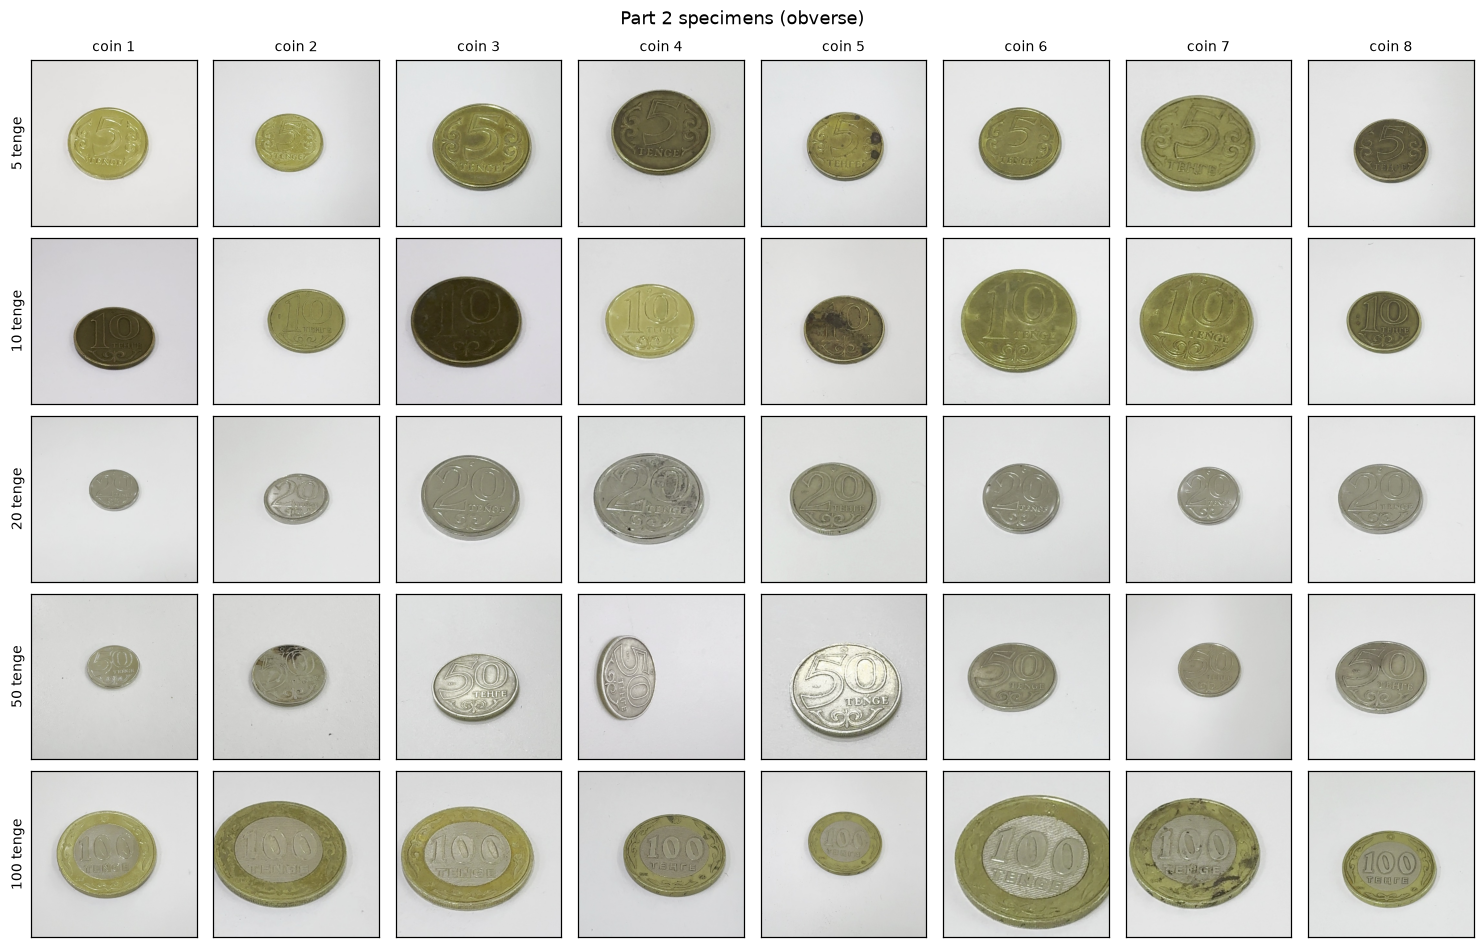

In [4]:
# The 25 specimens of Part 2: one obverse image per coin
fig, axes = plt.subplots(len(CLASSES), N_COINS, figsize=(N_COINS * 1.7, len(CLASSES) * 1.75))
for r, c in enumerate(CLASSES):
    for k in range(1, N_COINS + 1):
        ax = axes[r][k - 1]; ax.set_xticks([]); ax.set_yticks([])
        sub = p2[(p2.cls == c) & (p2.coin == f"c{k}") & (p2.side == "obverse")]
        if len(sub):
            ax.imshow(Image.open(sub.iloc[len(sub) // 2].path))
        if r == 0: ax.set_title(f"coin {k}", fontsize=9)
        if k == 1: ax.set_ylabel(f"{SHORT[r]} tenge", fontsize=9)
plt.suptitle("Part 2 specimens (obverse)"); plt.tight_layout(); savefig("p2_specimens.png"); plt.show()

In [5]:
def p1_split():
    return (p1[p1.setup.isin(P1_TRAIN_SETUPS)], p1[p1.setup == P1_VAL_SETUP], p1[p1.setup == P1_TEST_SETUP])

def p2_fold(k):
    test_coin, val_coin = f"c{k}", f"c{k % N_COINS + 1}"
    return (p2[~p2.coin.isin([test_coin, val_coin])], p2[p2.coin == val_coin], p2[p2.coin == test_coin])

def balanced_subsample(pool, target_counts, seed, groups):
    # Take target_counts[label] images per class from pool, spread evenly over the given groups
    rng = np.random.default_rng(seed)
    parts = []
    for lab, n in target_counts.items():
        sub = pool[pool.label == lab]
        buckets = [g.sample(frac=1, random_state=int(rng.integers(1_000_000_000)))
                   for _, g in sub.groupby(groups)]
        picked, i, n = [], 0, min(int(n), len(sub))
        while len(picked) < n:
            for g in buckets:
                if i < len(g) and len(picked) < n:
                    picked.append(g.index[i])
            i += 1
        parts.append(sub.loc[picked])
    return pd.concat(parts)

def e2_data(k, seed=E2_SEED):
    # Both training sets get the same number of images per class: the smaller of the two pools
    p2_tr, va, te = p2_fold(k)
    n = pd.concat([p1.label.value_counts(), p2_tr.label.value_counts()], axis=1).min(axis=1).sort_index()
    return ({"P1": balanced_subsample(p1, n, seed + k, ["setup", "side"]),
             "P2": balanced_subsample(p2_tr, n, seed + k, ["coin", "side"])}, va, te)

tr, va, te = p1_split()
print(f"Experiment 1: train {len(tr)} | val {len(va)} | test {len(te)}")
trs, va, te = e2_data(FOLDS[0])
print(f"Experiment 2, fold {FOLDS[0]}: P1 train {len(trs['P1'])} | P2 train {len(trs['P2'])} | "
      f"val {len(va)} ({va.coin.iloc[0]}) | test {len(te)} ({te.coin.iloc[0]})")
print("P1 train per setup:", trs["P1"].setup.value_counts().sort_index().to_dict())
print("P2 train per coin: ", trs["P2"].coin.value_counts().sort_index().to_dict())
print("Per class (P1 = P2):", trs["P1"].label.value_counts().sort_index().tolist(),
      trs["P2"].label.value_counts().sort_index().tolist())

Experiment 1: train 722 | val 194 | test 193
Experiment 2, fold 1: P1 train 1109 | P2 train 1109 | val 200 (c2) | test 191 (c1)
P1 train per setup: {1: 193, 2: 192, 3: 194, 4: 149, 5: 192, 6: 189}
P2 train per coin:  {'c3': 184, 'c4': 188, 'c5': 186, 'c6': 185, 'c7': 184, 'c8': 182}
Per class (P1 = P2): [220, 223, 217, 214, 235] [220, 223, 217, 214, 235]


## 2. Models and training
Same preprocessing and augmentation as Assignment 1 (224×224, ImageNet normalisation; rotation 0–360°, random resized crop, perspective, brightness/contrast, weak colour jitter, blur, no flips).

| | epochs (head + fine-tune) | fine-tune LR |
|---|---|---|
| Simple CNN | 0 + 30 | 1e-3 (Adam) |
| ResNet18 | 5 + 15 | 1e-4 (AdamW) |
| DINOv2 ViT-S/14 | 5 + 15 | 1e-5 backbone, 1e-4 head (AdamW) |
| DINOv2, frozen (ablation) | 20 + 0 | head only, 1e-3 (Adam) |

DINOv2 is trained in micro-batches of 8 with gradient accumulation over 4 steps (effective batch 32, the same as the other models): a batch of 32 does not fit into the GPU memory of a laptop. DINOv2 is loaded once and copied for every run. Its positional embedding is resized once to the 16×16 patch grid of 224×224 inputs, so no interpolation runs inside training (on Apple GPUs that operation falls back to the CPU and made training extremely slow).

The epoch with the lowest validation loss is kept; early stopping on validation loss.

In [6]:
IMG_SIZE, BATCH = 224, 32
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomRotation(180),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomApply([transforms.RandomPerspective(distortion_scale=0.25, p=1.0)], p=0.3),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.15, hue=0.02),
    transforms.RandomApply([transforms.GaussianBlur(5, sigma=(0.1, 1.5))], p=0.2),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class CoinDS(Dataset):
    def __init__(self, frame, tf):
        self.paths, self.labels, self.tf = frame.path.tolist(), frame.label.tolist(), tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        return self.tf(Image.open(self.paths[i]).convert("RGB")), self.labels[i]

def make_loaders(tr, va, te, seed, batch=BATCH):
    g = torch.Generator().manual_seed(seed)
    return (DataLoader(CoinDS(tr, train_tf), batch, shuffle=True, generator=g),
            DataLoader(CoinDS(va, eval_tf), batch), DataLoader(CoinDS(te, eval_tf), batch))

def denorm(t):
    return np.clip(t.permute(1, 2, 0).cpu().numpy() * np.array(STD) + np.array(MEAN), 0, 1)

class SimpleCNN(nn.Module):
    def __init__(self, n=len(CLASSES)):
        super().__init__()
        def block(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, n))
    def forward(self, x): return self.head(self.features(x))

_DINO_BASE = None

def dino_backbone():
    # DINOv2 ViT-S/14, downloaded once, with the positional embedding fixed to the 224x224 grid
    global _DINO_BASE
    if _DINO_BASE is None:
        m = torch.hub.load("facebookresearch/dinov2", "dinov2_vits14", trust_repo=True,
                           skip_validation=True, verbose=False)
        try:
            grid = IMG_SIZE // m.patch_size
            with torch.no_grad():
                dummy = torch.zeros(1, 1 + grid * grid, m.embed_dim)
                pe = m.interpolate_pos_encoding(dummy, IMG_SIZE, IMG_SIZE).detach().clone()
            m.pos_embed = nn.Parameter(pe)
            print(f"DINOv2: positional embedding fixed to a {grid}x{grid} grid")
        except Exception as e:
            print("WARNING: could not fix the DINOv2 positional embedding:", e)
        _DINO_BASE = m.eval()
    return copy.deepcopy(_DINO_BASE)

class DinoClassifier(nn.Module):
    def __init__(self, n=len(CLASSES), frozen=False):
        super().__init__()
        self.backbone = dino_backbone()
        self.head = nn.Linear(self.backbone.embed_dim, n)
        self.frozen = frozen
    def embed(self, x):                                   # normalised CLS token, 384-d
        if self.frozen:
            with torch.no_grad():
                return self.backbone(x)
        return self.backbone(x)
    def forward(self, x): return self.head(self.embed(x))

def make_model(name):
    if name == "simple_cnn":
        m = SimpleCNN(); head = None
    elif name == "resnet18":
        m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, len(CLASSES)); head = m.fc
    elif name == "dinov2_s":
        m = DinoClassifier(); head = m.head
    elif name == "dinov2_frozen":
        m = DinoClassifier(frozen=True); head = m.head
    else:
        raise ValueError(name)
    return m.to(DEVICE), head

# batch = images per forward pass; accum = passes per optimiser step (effective batch = batch * accum = 32).
# DINOv2 runs in micro-batches of 8: a batch of 32 does not fit into the GPU memory of a laptop Mac.
CFG = {"simple_cnn":    dict(head_epochs=0,  ft_epochs=30, ft_lr=1e-3, patience=8, batch=32, accum=1),
       "resnet18":      dict(head_epochs=5,  ft_epochs=15, ft_lr=1e-4, patience=5, batch=32, accum=1),
       "dinov2_s":      dict(head_epochs=5,  ft_epochs=15, ft_lr=1e-5, patience=5, batch=8,  accum=4),
       "dinov2_frozen": dict(head_epochs=20, ft_epochs=0,  ft_lr=0,    patience=5, batch=8,  accum=4)}
if FAST:
    for c in CFG.values():
        c.update(head_epochs=min(c["head_epochs"], 1), ft_epochs=min(c["ft_epochs"], 2), patience=2)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

def run_epoch(model, loader, criterion, optimizer=None, accum=1):
    training = optimizer is not None
    model.train(training)
    tot, correct, n = 0.0, 0, 0
    if training: optimizer.zero_grad()
    with torch.set_grad_enabled(training):
        for i, (x, y) in enumerate(loader):
            x, y = x.to(DEVICE), y.to(DEVICE)
            out = model(x); loss = criterion(out, y)
            if training:
                (loss / accum).backward()                       # gradient accumulation
                if (i + 1) % accum == 0 or i + 1 == len(loader):
                    optimizer.step(); optimizer.zero_grad()
            tot += loss.item() * len(y); correct += (out.argmax(1) == y).sum().item(); n += len(y)
    return tot / n, correct / n

def fit(model, trl, val, optimizer, epochs, scheduler=None, patience=5, history=None, verbose=True, accum=1):
    criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
    history = history or {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_loss = min(history["val_loss"], default=float("inf"))
    best_state, bad = copy.deepcopy(model.state_dict()), 0
    for _ in range(epochs):
        t0 = time.time()
        tl, ta = run_epoch(model, trl, criterion, optimizer, accum)
        vl, va_ = run_epoch(model, val, criterion)
        if scheduler is not None: scheduler.step()
        for k, v in zip(history, (tl, vl, ta, va_)): history[k].append(v)
        if verbose:
            log(f"    epoch {len(history['val_loss']):>2} | train loss {tl:.3f} acc {ta:.3f} | "
                f"val loss {vl:.3f} acc {va_:.3f} | {time.time() - t0:.0f}s")
        if vl < best_loss:
            best_loss, best_state, bad = vl, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state)
    return history

def train_model(name, tr, va, te, seed, verbose=True):
    set_seed(seed)
    cfg = CFG[name]
    model, head = make_model(name)
    trl, val, tel = make_loaders(tr, va, te, seed, cfg["batch"])
    acc_steps = cfg["accum"]
    hist = None
    if head is not None and cfg["head_epochs"]:
        for p in model.parameters(): p.requires_grad = False
        for p in head.parameters(): p.requires_grad = True
        hist = fit(model, trl, val, torch.optim.Adam(head.parameters(), lr=1e-3),
                   cfg["head_epochs"], patience=cfg["head_epochs"] if cfg["ft_epochs"] else cfg["patience"],
                   verbose=verbose, accum=acc_steps)
    if cfg["ft_epochs"] == 0:                     # frozen backbone: head training only
        return model, hist, tel
    for p in model.parameters(): p.requires_grad = True
    if name == "dinov2_s":
        opt = torch.optim.AdamW([{"params": model.backbone.parameters(), "lr": cfg["ft_lr"]},
                                 {"params": model.head.parameters(), "lr": cfg["ft_lr"] * 10}], weight_decay=0.05)
    elif name == "simple_cnn":
        opt = torch.optim.Adam(model.parameters(), lr=cfg["ft_lr"], weight_decay=1e-4)
    else:
        opt = torch.optim.AdamW(model.parameters(), lr=cfg["ft_lr"], weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg["ft_epochs"])
    hist = fit(model, trl, val, opt, cfg["ft_epochs"], sched, cfg["patience"], history=hist,
               verbose=verbose, accum=acc_steps)
    return model, hist, tel

@torch.no_grad()
def predict(model, loader):
    model.eval(); probs = []
    for x, _ in loader:
        probs.append(F.softmax(model(x.to(DEVICE)), 1).cpu())
    probs = torch.cat(probs).numpy()
    return probs.argmax(1), probs

In [7]:
# Run bookkeeping (no torch needed): one .npz file per finished run
def run_id(exp, model, src, fold, seed):
    return f"{exp}__{model}__{src}__f{fold}__s{seed}"

def run_file(rid):
    return OUT / "runs" / f"{rid}.npz"

def save_run(rid, te, pred, prob, hist, seconds, n_train):
    np.savez(run_file(rid), pred=pred, prob=prob, y=te.label.to_numpy(), paths=np.array(te.path.tolist()),
             hist=json.dumps(hist), seconds=seconds, n_train=n_train)

def load_runs():
    rows = []
    for f in sorted((OUT / "runs").glob("*.npz")):
        exp, model, src, fold, seed = f.stem.split("__")
        d = np.load(f)
        rows.append(dict(rid=f.stem, exp=exp, model=model, src=src, fold=int(fold[1:]), seed=int(seed[1:]),
                         acc=accuracy_score(d["y"], d["pred"]),
                         f1=f1_score(d["y"], d["pred"], average="macro", labels=range(len(CLASSES)), zero_division=0),
                         seconds=float(d["seconds"]), n_train=int(d["n_train"])))
    return pd.DataFrame(rows)

def load_pred(rid):
    d = np.load(run_file(rid))
    return d["y"], d["pred"], d["prob"], d["paths"], json.loads(str(d["hist"]))

In [8]:
def run_one(exp, model_name, src, fold, seed, tr, va, te, save_weights=False):
    rid = run_id(exp, model_name, src, fold, seed)
    if run_file(rid).exists():
        print(f"{rid}: done earlier, skipped"); return
    log(f"START {rid} | train {len(tr)} | val {len(va)} | test {len(te)}")
    t0 = time.time()
    model, hist, tel = train_model(model_name, tr, va, te, seed)
    pred, prob = predict(model, tel)
    secs = time.time() - t0
    save_run(rid, te, pred, prob, hist, secs, len(tr))
    if save_weights:
        torch.save(model.state_dict(), OUT / "weights" / f"{rid}.pt")
    log(f"DONE  {rid}: test acc {accuracy_score(te.label, pred):.3f} | "
        f"{len(hist['val_loss'])} epochs | {secs / 60:.1f} min")
    del model
    if DEVICE == "mps": torch.mps.empty_cache()

## 3. Speed check
Three training steps of every model on one batch. Prints the expected time per epoch and for the whole run. If DINOv2 shows several seconds per step or more, stop and report before leaving the notebook overnight.

In [9]:
def speed_check(n_steps=3):
    # Time of one optimiser step (effective batch 32) per model
    tr, va, te = p1_split()
    out = {}
    for name in MODELS:
        cfg = CFG[name]
        x, y = next(iter(make_loaders(tr, va, te, 0, cfg["batch"])[0]))
        x, y = x.to(DEVICE), y.to(DEVICE)
        model, _ = make_model(name); model.train()
        opt = torch.optim.AdamW(model.parameters(), lr=1e-5)
        times = []
        for i in range(n_steps + 1):
            t0 = time.time()
            loss = F.cross_entropy(model(x), y)
            opt.zero_grad(); loss.backward(); opt.step()
            if DEVICE == "mps": torch.mps.synchronize()
            if i > 0: times.append(time.time() - t0)   # step 0 = warm-up
        out[name] = float(np.mean(times)) * cfg["accum"]
        del model
        if DEVICE == "mps": torch.mps.empty_cache()
    return out

step = speed_check()
batches_e1 = int(np.ceil(len(p1_split()[0]) / BATCH))
batches_e2 = int(np.ceil(len(e2_data(FOLDS[0])[0]["P2"]) / BATCH))
total = 0.0
for name, t in step.items():
    epochs = CFG[name]["head_epochs"] + CFG[name]["ft_epochs"]
    e1_min = t * batches_e1 * 1.4 * epochs / 60          # 1.4 ~ validation + test overhead
    e2_min = t * batches_e2 * 1.4 * epochs / 60
    n_e2 = 2 * len(FOLDS)
    total += e1_min * len(SEEDS) + e2_min * n_e2
    log(f"speed {MODEL_LABEL[name]:<16} {t:.2f} s/step | E1 run ≤{e1_min:.0f} min | E2 run ≤{e2_min:.0f} min")
if RUN_ABLATION:
    total += step["dinov2_s"] * 0.4 * batches_e1 * 1.4 * CFG["dinov2_frozen"]["head_epochs"] / 60 * len(SEEDS)
log(f"Upper estimate for all runs (no early stopping): {total / 60:.1f} h; already finished runs are skipped")

DINOv2: positional embedding fixed to a 16x16 grid
[23:26:11] speed Simple CNN       0.23 s/step | E1 run ≤4 min | E2 run ≤6 min
[23:26:11] speed ResNet18         0.28 s/step | E1 run ≤3 min | E2 run ≤5 min
[23:26:11] speed DINOv2 ViT-S/14  1.39 s/step | E1 run ≤15 min | E2 run ≤23 min
[23:26:11] Upper estimate for all runs (no early stopping): 10.1 h; already finished runs are skipped


## 4. Run all experiments
Order: Simple CNN and ResNet18 (Experiment 1, then Experiment 2) → DINOv2 (Experiment 1, then Experiment 2) → ablation.
Weights of the first Experiment 2 fold are kept for the Grad-CAM and nearest-neighbour figures.

In [10]:
def tasks_for(models):
    for m in models:
        tr, va, te = p1_split()
        for seed in SEEDS:
            yield ("E1", m, "P1", 0, seed, tr, va, te, False)
    for m in models:
        for k in FOLDS:
            trs, va, te = e2_data(k)
            for src in ["P1", "P2"]:
                yield ("E2", m, src, k, E2_SEED, trs[src], va, te, k == FOLDS[0] and m != "simple_cnn")

log("===== run started =====")
for task in tasks_for(["simple_cnn", "resnet18"]):
    run_one(*task[:8], save_weights=task[8])
for task in tasks_for(["dinov2_s"]):
    run_one(*task[:8], save_weights=task[8])
if RUN_ABLATION:
    tr, va, te = p1_split()
    for seed in SEEDS:
        run_one("E1", "dinov2_frozen", "P1", 0, seed, tr, va, te)
log("===== all runs finished =====")

[23:26:11] ===== run started =====
[23:26:11] START E1__simple_cnn__P1__f0__s42 | train 722 | val 194 | test 193
[23:26:20]     epoch  1 | train loss 1.688 acc 0.199 | val loss 1.587 acc 0.216 | 9s
[23:26:31]     epoch  2 | train loss 1.508 acc 0.299 | val loss 1.685 acc 0.206 | 11s
[23:26:40]     epoch  3 | train loss 1.438 acc 0.385 | val loss 1.934 acc 0.196 | 9s
[23:26:49]     epoch  4 | train loss 1.397 acc 0.377 | val loss 1.796 acc 0.247 | 9s
[23:26:58]     epoch  5 | train loss 1.364 acc 0.421 | val loss 1.541 acc 0.247 | 9s
[23:27:08]     epoch  6 | train loss 1.405 acc 0.375 | val loss 1.657 acc 0.284 | 10s
[23:27:17]     epoch  7 | train loss 1.383 acc 0.363 | val loss 1.753 acc 0.299 | 9s
[23:27:26]     epoch  8 | train loss 1.343 acc 0.385 | val loss 1.667 acc 0.216 | 9s
[23:27:34]     epoch  9 | train loss 1.315 acc 0.432 | val loss 1.761 acc 0.216 | 9s
[23:27:43]     epoch 10 | train loss 1.291 acc 0.431 | val loss 1.831 acc 0.253 | 9s
[23:27:52]     epoch 11 | train los

## 5. Results

In [11]:
runs = load_runs()
runs.to_csv(OUT / "all_runs.csv", index=False)
pm = lambda s: f"{s.mean():.3f} ± {s.std(ddof=0):.3f}" if len(s) > 1 else f"{s.mean():.3f}"

e1_all = runs[runs.exp == "E1"]
e1 = e1_all[e1_all.model.isin(MODELS)]
table_e1 = (e1.groupby("model").agg(accuracy=("acc", pm), macro_f1=("f1", pm),
                                     train_min=("seconds", lambda s: f"{s.mean() / 60:.1f}"))
              .reindex(MODELS).rename(index=MODEL_LABEL))
table_e1.to_csv(OUT / "table_e1.csv")
print(f"Experiment 1 — same coin, unseen lighting (mean ± std over {e1.seed.nunique()} seeds)")
table_e1

Experiment 1 — same coin, unseen lighting (mean ± std over 3 seeds)


,accuracy,macro_f1,train_min
model,,,
Simple CNN,0.302 ± 0.039,0.223 ± 0.042,2.7
ResNet18,0.965 ± 0.005,0.966 ± 0.004,2.6
DINOv2 ViT-S/14,0.995 ± 0.004,0.995 ± 0.004,8.8


In [12]:
e2 = runs[runs.exp == "E2"]
table_e2 = (e2.groupby(["model", "src"]).agg(accuracy=("acc", pm), macro_f1=("f1", pm))
              .unstack("src").reindex(MODELS).rename(index=MODEL_LABEL))
table_e2.to_csv(OUT / "table_e2.csv")
print(f"Experiment 2 — unseen coins, known conditions (mean ± std over {e2.fold.nunique()} folds)")
display(table_e2)

# Specimen gap: P1-trained models on their own coin (E1) vs on new coins (E2)
gap = pd.DataFrame({
    "E1: same coin, new light": e1.groupby("model").acc.mean(),
    "E2: new coins (P1-trained)": e2[e2.src == "P1"].groupby("model").acc.mean(),
    "E2: new coins (P2-trained)": e2[e2.src == "P2"].groupby("model").acc.mean()}).reindex(MODELS)
gap["specimen gap (E1 − E2 P1)"] = gap.iloc[:, 0] - gap.iloc[:, 1]
gap = gap.rename(index=MODEL_LABEL)
gap.to_csv(OUT / "table_specimen_gap.csv")
print("Accuracy summary")
display(gap.style.format("{:.3f}"))

per_fold = e2.pivot_table(index=["model", "src"], columns="fold", values="acc").reindex(MODELS, level=0)
per_fold.to_csv(OUT / "table_e2_per_fold.csv")
print("Experiment 2 — accuracy per fold (test coin = fold number)")
display(per_fold.style.format("{:.3f}"))

Experiment 2 — unseen coins, known conditions (mean ± std over 8 folds)


accuracy                      macro_f1               
src                         P1             P2             P1             P2
model                                                                      
Simple CNN       0.308 ± 0.038  0.687 ± 0.115  0.227 ± 0.047  0.670 ± 0.121
ResNet18         0.413 ± 0.092  0.710 ± 0.114  0.384 ± 0.069  0.686 ± 0.126
DINOv2 ViT-S/14  0.442 ± 0.109  0.768 ± 0.115  0.407 ± 0.111  0.761 ± 0.118

Accuracy summary


,"E1: same coin, new light",E2: new coins (P1-trained),E2: new coins (P2-trained),specimen gap (E1 − E2 P1)
model,,,,
Simple CNN,0.302,0.308,0.687,-0.006
ResNet18,0.965,0.413,0.710,0.553
DINOv2 ViT-S/14,0.995,0.442,0.768,0.553


Experiment 2 — accuracy per fold (test coin = fold number)


In [13]:
# Ablation (Assignment 2): DINOv2 frozen vs fine-tuned, Experiment 1 split
abl = e1_all[e1_all.model.isin(["dinov2_frozen", "dinov2_s"])]
if len(abl):
    table_abl = (abl.groupby("model").agg(accuracy=("acc", pm), macro_f1=("f1", pm),
                                          train_min=("seconds", lambda s: f"{s.mean() / 60:.1f}"))
                   .reindex(["dinov2_frozen", "dinov2_s"]).rename(index=MODEL_LABEL))
    table_abl.to_csv(OUT / "table_ablation.csv")
    display(table_abl)

,accuracy,macro_f1,train_min
model,,,
"DINOv2, frozen backbone",0.872 ± 0.020,0.871 ± 0.021,3.2
DINOv2 ViT-S/14,0.995 ± 0.004,0.995 ± 0.004,8.8


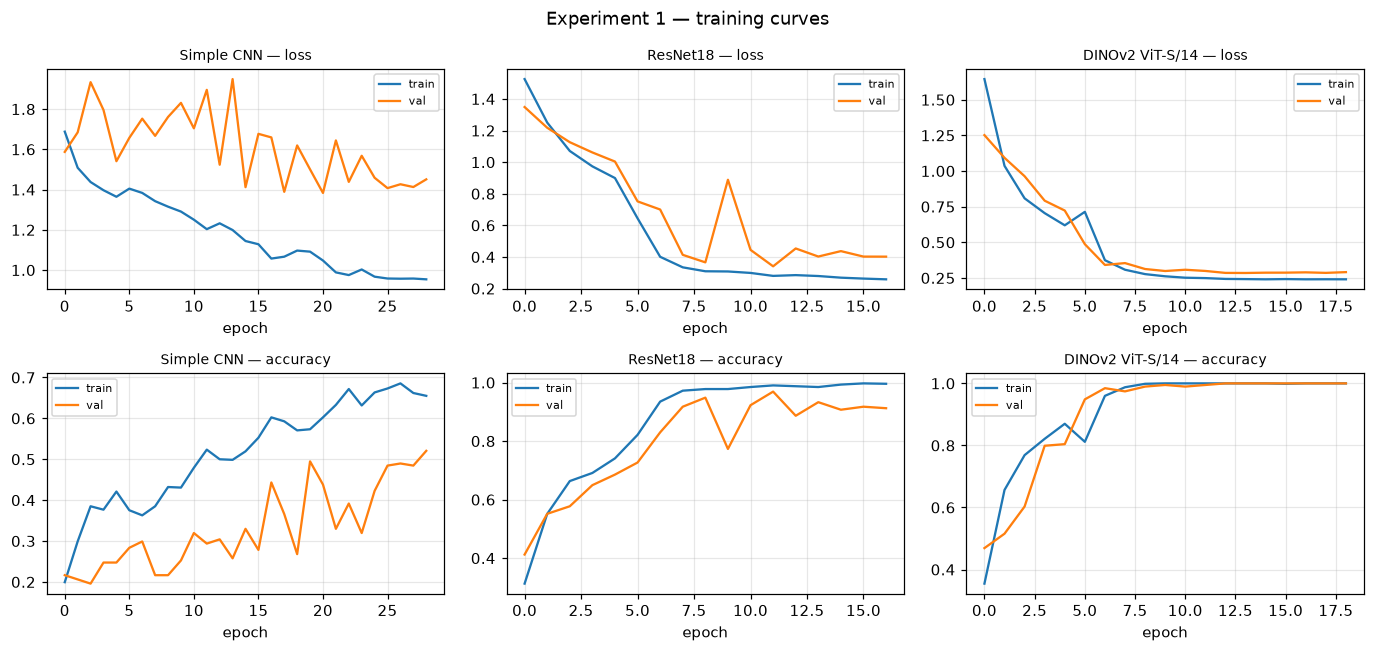

In [14]:
# Training curves, Experiment 1, first seed
fig, axes = plt.subplots(2, len(MODELS), figsize=(4.2 * len(MODELS), 6), squeeze=False)
for j, m in enumerate(MODELS):
    rid = run_id("E1", m, "P1", 0, SEEDS[0])
    if not run_file(rid).exists(): continue
    h = load_pred(rid)[4]
    axes[0][j].plot(h["train_loss"], label="train"); axes[0][j].plot(h["val_loss"], label="val")
    axes[1][j].plot(h["train_acc"], label="train");  axes[1][j].plot(h["val_acc"], label="val")
    axes[0][j].set_title(f"{MODEL_LABEL[m]} — loss", fontsize=9); axes[1][j].set_title(f"{MODEL_LABEL[m]} — accuracy", fontsize=9)
    for a in axes[:, j]: a.grid(alpha=0.3); a.legend(fontsize=7); a.set_xlabel("epoch")
plt.suptitle("Experiment 1 — training curves"); plt.tight_layout(); savefig("e1_curves.png"); plt.show()

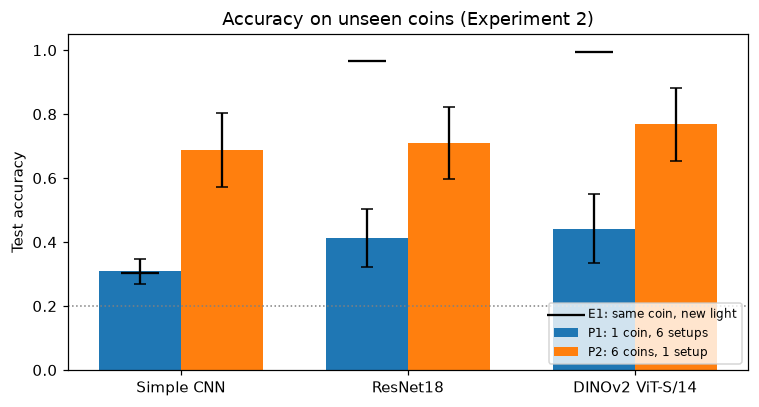

In [15]:
x = np.arange(len(MODELS)); w = 0.36
fig, ax = plt.subplots(figsize=(7, 3.8))
for j, src in enumerate(["P1", "P2"]):
    s = e2[e2.src == src].groupby("model").acc
    ax.bar(x + (j - 0.5) * w, s.mean().reindex(MODELS), w, yerr=s.std(ddof=0).reindex(MODELS).fillna(0),
           capsize=4, label=SRC_LABEL[src])
e1m = e1.groupby("model").acc.mean().reindex(MODELS)
ax.scatter(x - 0.5 * w, e1m, marker="_", s=600, color="k", zorder=3, label="E1: same coin, new light")
ax.set_xticks(x); ax.set_xticklabels([MODEL_LABEL[m] for m in MODELS])
ax.set_ylabel("Test accuracy"); ax.set_ylim(0, 1.05); ax.axhline(0.2, ls=":", c="gray", lw=1)
ax.set_title("Accuracy on unseen coins (Experiment 2)"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); savefig("e2_accuracy.png"); plt.show()

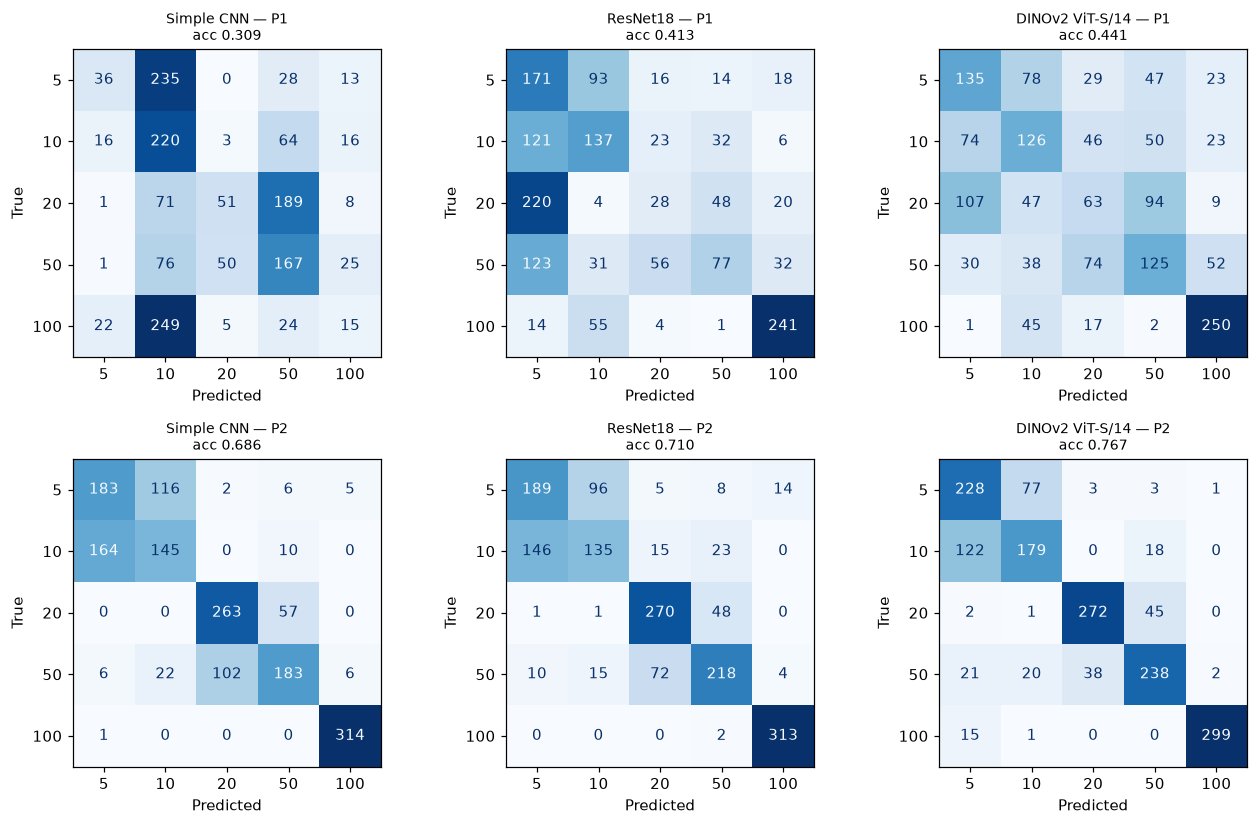

In [16]:
# Confusion matrices of Experiment 2, summed over all folds
fig, axes = plt.subplots(2, len(MODELS), figsize=(4 * len(MODELS), 7.6))
for j, m in enumerate(MODELS):
    for i, src in enumerate(["P1", "P2"]):
        ys, ps = [], []
        for rid in e2[(e2.model == m) & (e2.src == src)].rid:
            y, p, *_ = load_pred(rid); ys.append(y); ps.append(p)
        ax = axes[i][j]
        if not ys: ax.axis("off"); continue
        y, p = np.concatenate(ys), np.concatenate(ps)
        ConfusionMatrixDisplay(confusion_matrix(y, p, labels=range(len(CLASSES))), display_labels=SHORT).plot(
            ax=ax, colorbar=False, cmap="Blues")
        ax.set_title(f"{MODEL_LABEL[m]} — {src}\nacc {accuracy_score(y, p):.3f}", fontsize=9)
        ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout(); savefig("e2_confusion.png"); plt.show()

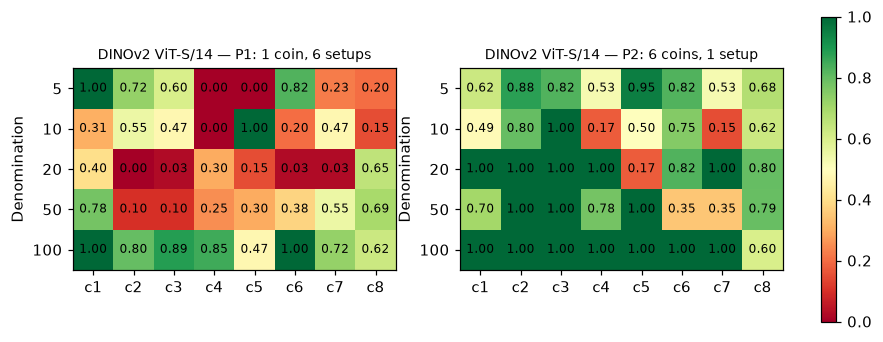

In [17]:
# Which specimens are hard? Accuracy per (denomination, coin) in Experiment 2
def coin_accuracy(model, src):
    rows = []
    for rid in e2[(e2.model == model) & (e2.src == src)].rid:
        y, p, _, paths, _ = load_pred(rid)
        for yy, pp, path in zip(y, p, paths):
            m = P2_RE.search(Path(str(path)).name)
            rows.append(dict(cls=SHORT[yy], coin=int(m.group(1)), ok=int(yy == pp)))
    d = pd.DataFrame(rows)
    return d.pivot_table(index="cls", columns="coin", values="ok", aggfunc="mean").reindex(SHORT)

best = e2[e2.src == "P2"].groupby("model").acc.mean().idxmax()
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, src in zip(axes, ["P1", "P2"]):
    tab = coin_accuracy(best, src)
    im = ax.imshow(tab.values, vmin=0, vmax=1, cmap="RdYlGn")
    ax.set_xticks(range(tab.shape[1])); ax.set_xticklabels([f"c{c}" for c in tab.columns])
    ax.set_yticks(range(len(SHORT))); ax.set_yticklabels(SHORT); ax.set_ylabel("Denomination")
    for (r, c), v in np.ndenumerate(tab.values):
        if not np.isnan(v): ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(f"{MODEL_LABEL[best]} — {SRC_LABEL[src]}", fontsize=9)
plt.colorbar(im, ax=axes, fraction=0.025); savefig("e2_per_coin.png"); plt.show()

In [18]:
# Accuracy by coin side in Experiment 2
rows = []
for _, r in e2.iterrows():
    y, p, _, paths, _ = load_pred(r.rid)
    sides = np.array([side_of(P2_RE.search(Path(str(s)).name).group(2)) for s in paths])
    for sd in ["obverse", "reverse"]:
        mask = sides == sd
        rows.append(dict(model=MODEL_LABEL[r.model], src=r.src, side=sd, acc=(y[mask] == p[mask]).mean()))
by_side = pd.DataFrame(rows).pivot_table(index=["model", "src"], columns="side", values="acc", aggfunc="mean")
by_side.to_csv(OUT / "table_e2_by_side.csv")
by_side.style.format("{:.3f}")

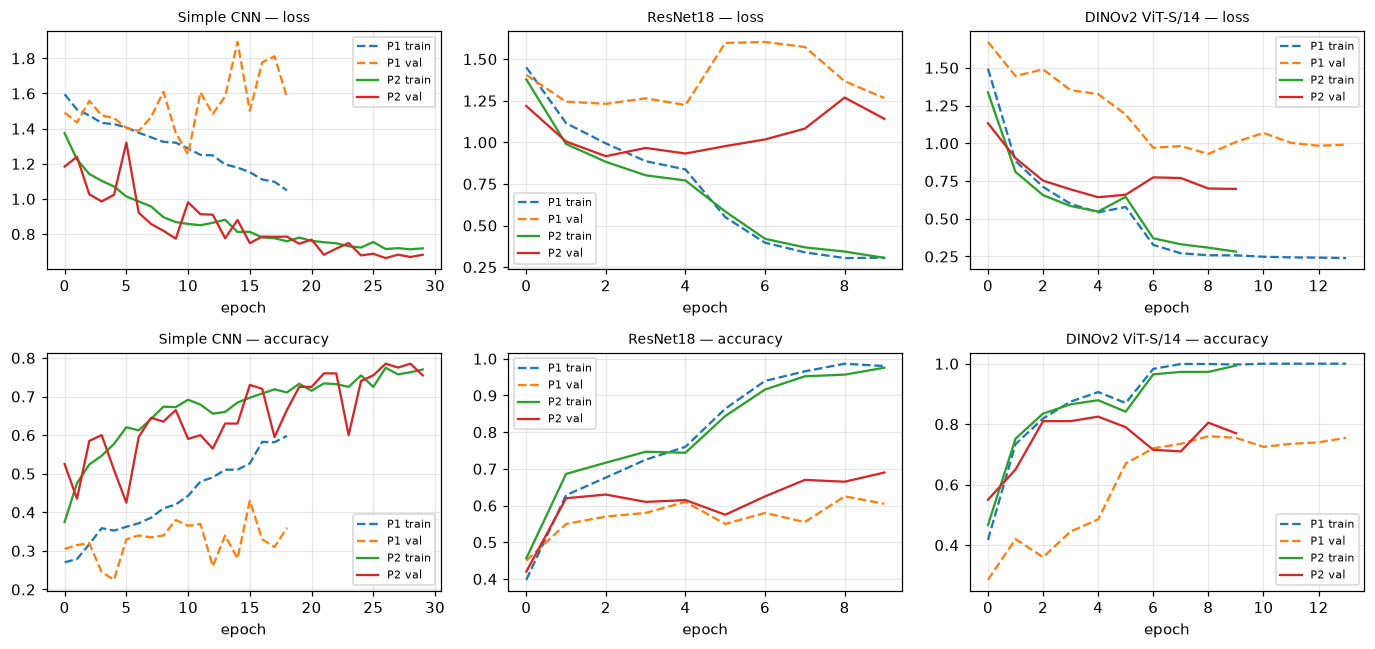

In [19]:
# Training curves, Experiment 2, first fold
fig, axes = plt.subplots(2, len(MODELS), figsize=(4.2 * len(MODELS), 6), squeeze=False)
for j, m in enumerate(MODELS):
    for src, style in [("P1", "--"), ("P2", "-")]:
        rid = run_id("E2", m, src, FOLDS[0], E2_SEED)
        if not run_file(rid).exists(): continue
        h = load_pred(rid)[4]
        axes[0][j].plot(h["train_loss"], style, label=f"{src} train"); axes[0][j].plot(h["val_loss"], style, label=f"{src} val")
        axes[1][j].plot(h["train_acc"], style, label=f"{src} train");  axes[1][j].plot(h["val_acc"], style, label=f"{src} val")
    axes[0][j].set_title(f"{MODEL_LABEL[m]} — loss", fontsize=9); axes[1][j].set_title(f"{MODEL_LABEL[m]} — accuracy", fontsize=9)
    for a in axes[:, j]: a.grid(alpha=0.3); a.legend(fontsize=7); a.set_xlabel("epoch")
plt.tight_layout(); savefig("e2_curves_fold1.png"); plt.show()

## 6. Explainability (first fold)
**Grad-CAM, ResNet18:** the same unseen test coins seen by the P1-trained and the P2-trained model.
**Nearest neighbours, DINOv2 (P2-trained):** the most similar training images in the model's embedding space — shows which specimen a decision is based on.

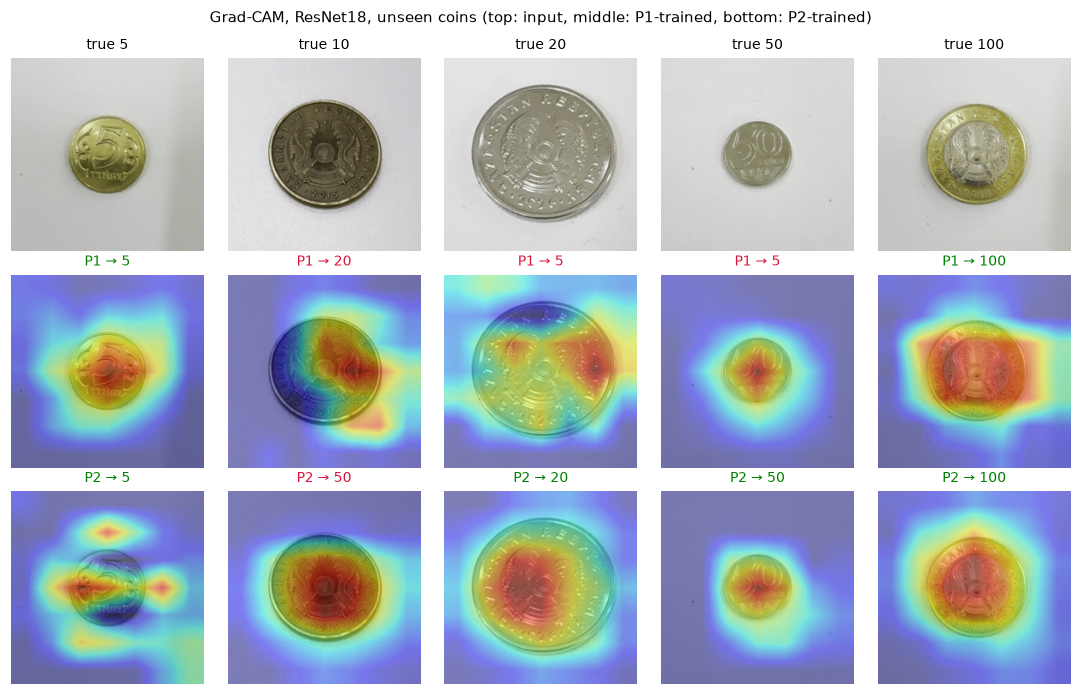

In [20]:
def grad_cam(model, x, layer):
    store = {}
    def hook(_, __, out):
        store["a"] = out
        out.register_hook(lambda g: store.__setitem__("g", g))
    h = layer.register_forward_hook(hook)
    model.eval()
    out = model(x.unsqueeze(0).to(DEVICE).requires_grad_(True))
    h.remove()
    idx = out.argmax(1).item()
    model.zero_grad(); out[0, idx].backward()
    w = store["g"].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * store["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.detach().cpu().numpy(), idx

def load_weights(model_name, src):
    m, _ = make_model(model_name)
    m.load_state_dict(torch.load(OUT / "weights" / f"{run_id('E2', model_name, src, FOLDS[0], E2_SEED)}.pt",
                                 map_location=DEVICE))
    return m.eval()

_, _, te = p2_fold(FOLDS[0])
picks = te.groupby("label").sample(1, random_state=0).sort_values("label")
nets = {src: load_weights("resnet18", src) for src in ["P1", "P2"]}

fig, axes = plt.subplots(3, len(picks), figsize=(len(picks) * 2, 6.4))
for k, (_, r) in enumerate(picks.iterrows()):
    x = eval_tf(Image.open(r.path).convert("RGB"))
    axes[0][k].imshow(denorm(x)); axes[0][k].set_title(f"true {SHORT[r.label]}", fontsize=9)
    for i, src in enumerate(["P1", "P2"], start=1):
        cam, idx = grad_cam(nets[src], x, nets[src].layer4[-1])
        axes[i][k].imshow(denorm(x)); axes[i][k].imshow(cam, cmap="jet", alpha=0.45)
        axes[i][k].set_title(f"{src} → {SHORT[idx]}", fontsize=9, color="green" if idx == r.label else "crimson")
for a in axes.flat: a.axis("off")
plt.suptitle("Grad-CAM, ResNet18, unseen coins (top: input, middle: P1-trained, bottom: P2-trained)", fontsize=10)
plt.tight_layout(); savefig("gradcam_p1_vs_p2.png"); plt.show()

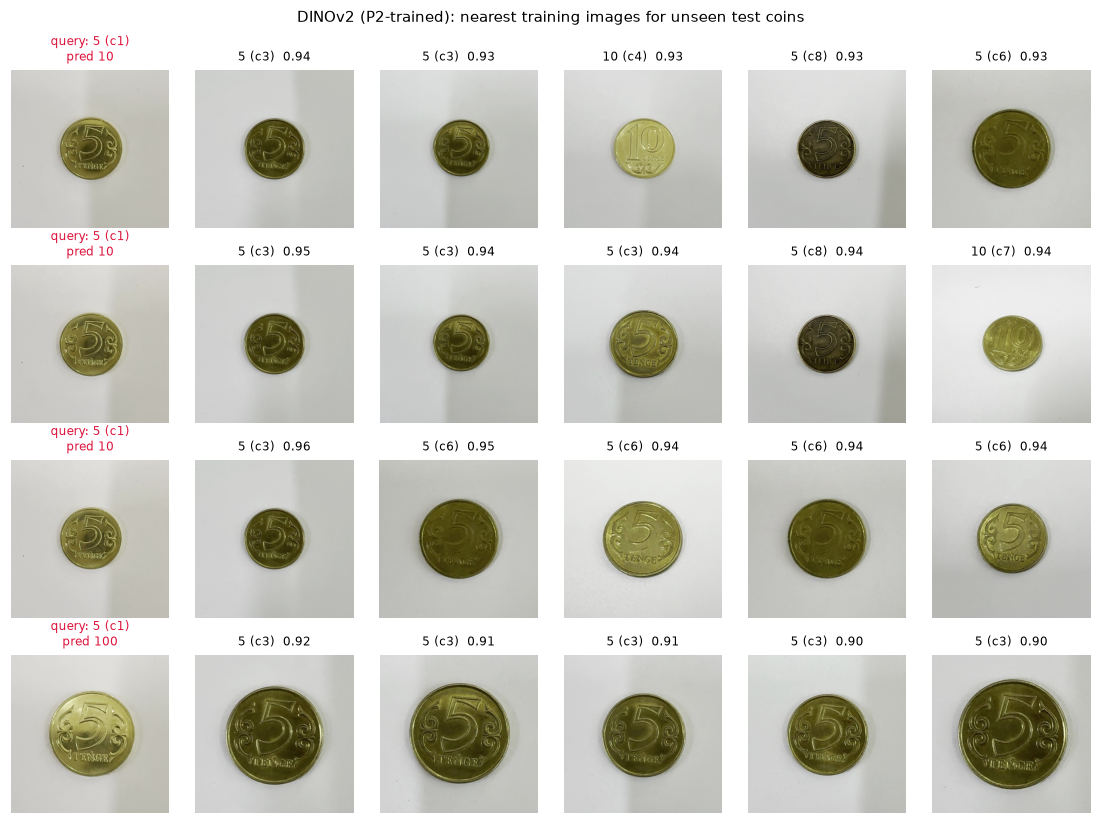

In [21]:
@torch.no_grad()
def embed_frame(model, frame):
    model.eval(); embs = []
    b = CFG["dinov2_s"]["batch"]
    for i in range(0, len(frame), b):
        xb = torch.stack([eval_tf(Image.open(p).convert("RGB")) for p in frame.path.iloc[i:i + b]])
        embs.append(F.normalize(model.embed(xb.to(DEVICE)), dim=1).cpu())
    return torch.cat(embs).numpy()

dino = load_weights("dinov2_s", "P2")
tr, va, te = p2_fold(FOLDS[0])
tr, te = tr.reset_index(drop=True), te.reset_index(drop=True)
E_tr, E_te = embed_frame(dino, tr), embed_frame(dino, te)

y, pred, *_ = load_pred(run_id("E2", "dinov2_s", "P2", FOLDS[0], E2_SEED))
wrong = list(np.where(pred != y)[0])
queries = (wrong + list(te.groupby("label").sample(1, random_state=1).index))[:4]
K = 5
fig, axes = plt.subplots(len(queries), K + 1, figsize=((K + 1) * 1.7, len(queries) * 1.9), squeeze=False)
for r, qi in enumerate(queries):
    sims = E_tr @ E_te[qi]
    nn_idx = np.argsort(-sims)[:K]
    axes[r][0].imshow(Image.open(te.path[qi]))
    axes[r][0].set_title(f"query: {SHORT[te.label[qi]]} ({te.coin[qi]})\npred {SHORT[pred[qi]]}", fontsize=8,
                         color="green" if pred[qi] == y[qi] else "crimson")
    for c, j in enumerate(nn_idx, start=1):
        axes[r][c].imshow(Image.open(tr.path[j]))
        axes[r][c].set_title(f"{SHORT[tr.label[j]]} ({tr.coin[j]})  {sims[j]:.2f}", fontsize=8)
for a in axes.flat: a.axis("off")
plt.suptitle("DINOv2 (P2-trained): nearest training images for unseen test coins", fontsize=10)
plt.tight_layout(); savefig("dinov2_neighbours.png"); plt.show()

## 7. Notes for the paper
All tables are in `results_paper/*.csv`, all figures in `results_paper/figures/`, every run in `results_paper/all_runs.csv`.